# Chapter 5 — Classification
**Sumber:** *Practical Statistics for Data Scientists*, 2nd Ed. (Bruce, Bruce & Gedeck, O'Reilly)

Notebook ini mereproduksi kode Python dari Chapter 5 dan menjelaskan teori di baliknya.

**Tujuan chapter:** Banyak masalah data science berbentuk **klasifikasi**: memprediksi apakah sebuah record termasuk kelas tertentu. Contohnya apakah pinjaman akan *default* atau lunas (*paid off*), apakah email adalah spam, atau apakah pelanggan akan *churn*. Chapter ini membahas:
- tiga metode klasifikasi klasik berbasis statistika: **Naive Bayes**, **Discriminant Analysis**, dan **Logistic Regression**;
- cara **mengevaluasi** model klasifikasi: *confusion matrix*, *precision/recall/specificity*, kurva **ROC**, **AUC**, dan **lift**;
- **strategi untuk data tidak seimbang** (*imbalanced data*): undersampling, oversampling/up-weighting, pembangkitan data (SMOTE), klasifikasi berbasis biaya, dan eksplorasi prediksi.

**Pendekatan umum klasifikasi.** Hampir semua algoritma tidak langsung menghasilkan label, melainkan **probabilitas** (atau *propensity score*) bahwa record termasuk kelas yang diminati. Langkahnya:
1. Tentukan *cutoff* probabilitas (misalnya 0,5).
2. Estimasi probabilitas $P(Y=1 \mid X)$ dengan suatu model.
3. Jika probabilitas di atas *cutoff*, beri label kelas 1.

*Cutoff* yang lebih rendah menghasilkan lebih banyak prediksi kelas 1 (lebih sensitif), sedangkan *cutoff* yang lebih tinggi menghasilkan lebih sedikit. Untuk lebih dari dua kelas, masalah sering dipecah menjadi beberapa masalah biner (misalnya *one-vs-rest*) atau diselesaikan secara bersyarat.

**Dataset utama:** data pinjaman Lending Club (`loan_data.csv.gz`, 45.342 pinjaman yang seimbang antara *default* dan *paid off*), sampel kecil `loan3000.csv`, dan data lengkap yang tidak seimbang `full_train_set.csv.gz`.

## Import Library

In [1]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np

from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.metrics import roc_curve, accuracy_score, roc_auc_score
from sklearn.preprocessing import OrdinalEncoder

import statsmodels.api as sm
import statsmodels.formula.api as smf

from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler
from pygam import LinearGAM, s, f, l

from dmba import classificationSummary, liftChart, gainsChart

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
%matplotlib inline

In [3]:
# Lokasi folder data (folder `data/` berada satu level di atas folder `notebooks/`)
DATA = Path('../data')
if not DATA.exists():          # cadangan jika notebook dijalankan dari root repo
    DATA = Path('data')
print('Folder data ditemukan:', DATA.resolve().exists())

Folder data ditemukan: True


## Definisi Path Dataset

In [4]:
LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
FULL_TRAIN_SET_CSV = DATA / 'full_train_set.csv.gz'

## 5.1 Naive Bayes
### Mengapa Klasifikasi Bayesian Eksak Tidak Praktis
**Teori:** Klasifikasi Bayesian **eksak** bekerja seperti ini: untuk record baru, cari **semua record lain yang profil prediktornya identik**, lalu lihat kelas mana yang paling sering muncul di antara record-record tersebut. Prediksinya adalah kelas mayoritas, yaitu estimasi empiris dari $P(Y=i \mid X_1, \ldots, X_p)$.

Masalahnya, begitu jumlah prediktor bertambah, kombinasi nilai prediktor meledak secara eksponensial. Dengan hanya 5 prediktor biner sudah ada $2^5 = 32$ profil. Dengan puluhan prediktor, hampir pasti **tidak ada** record lain yang cocok persis dengan record baru. Karena itu metode eksak tidak bisa dipakai.

### The Naive Solution
**Teori:** Naive Bayes tidak lagi mensyaratkan kecocokan persis. Ia memakai **seluruh data** dengan asumsi "naif" bahwa **prediktor saling independen secara bersyarat, diberikan kelasnya**. Langkahnya:
1. Untuk setiap kelas $Y=i$ dan setiap prediktor $X_j$, hitung probabilitas bersyarat $P(X_j \mid Y=i)$, yaitu proporsi nilai $X_j$ di antara record kelas $i$.
2. Kalikan semua probabilitas itu dengan *prior* kelas $P(Y=i)$.
3. Normalisasi terhadap jumlah dari semua kelas.

$$P(Y=i \mid X_1,\ldots,X_p) = \frac{P(Y=i)\,P(X_1\mid Y=i)\cdots P(X_p\mid Y=i)}{\sum_{k} P(Y=k)\,P(X_1\mid Y=k)\cdots P(X_p\mid Y=k)}$$

Rumus ini berasal dari **teorema Bayes** ditambah asumsi independensi bersyarat, sehingga $P(X_1,\ldots,X_p\mid Y=i) = \prod_j P(X_j\mid Y=i)$.

**Catatan penting:**
- Asumsi independensi hampir selalu dilanggar. Akibatnya **estimasi probabilitasnya bias**, tetapi **urutan (ranking)** probabilitas sering tetap baik, sehingga klasifikasinya cukup akurat.
- Naive Bayes klasik bekerja dengan **prediktor kategorikal**. Prediktor numerik harus di-*binning* menjadi kategori, atau dimodelkan dengan distribusi (misalnya normal, seperti *Gaussian Naive Bayes*).
- Jika ada kategori yang tidak pernah muncul pada suatu kelas, probabilitasnya 0 dan seluruh perkalian ikut menjadi 0. Untuk mencegahnya dipakai **Laplace smoothing**, yaitu parameter `alpha` di scikit-learn.

**Data:** `loan_data` dengan tiga prediktor kategorikal: `purpose_` (tujuan pinjaman), `home_` (status kepemilikan rumah), dan `emp_len_` (lama bekerja). Prediktor diubah menjadi variabel dummy (*one-hot*) dan dimodelkan dengan `MultinomialNB`.

In [5]:
loan_data = pd.read_csv(LOAN_DATA_CSV)

# ubah menjadi kategorikal
loan_data.outcome = loan_data.outcome.astype('category')
# Catatan: di kode asli, `reorder_categories` dipanggil tanpa disimpan sehingga tidak berpengaruh.
# Urutan kategori tetap ['default', 'paid off'] (alfabetis); urutan ini dipertahankan di sini.
loan_data.purpose_ = loan_data.purpose_.astype('category')
loan_data.home_ = loan_data.home_.astype('category')
loan_data.emp_len_ = loan_data.emp_len_.astype('category')

predictors = ['purpose_', 'home_', 'emp_len_']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='', dtype=int)
y = loan_data[outcome]

# alpha sangat kecil = (hampir) tanpa Laplace smoothing; fit_prior=False = prior seragam
naive_model = MultinomialNB(alpha=1e-10, fit_prior=False)
naive_model.fit(X, y)

new_loan = X.loc[146:146, :]
print('predicted class: ', naive_model.predict(new_loan)[0])

probabilities = pd.DataFrame(naive_model.predict_proba(new_loan),
                             columns=naive_model.classes_)
print('predicted probabilities',)
print(probabilities)

predicted class:  default
predicted probabilities
    default  paid off
0  0.653699  0.346301


In [6]:
# Profil record baru (pinjaman ke-147) dalam bentuk kategori aslinya
print(loan_data.loc[146, predictors])
print('outcome sebenarnya:', loan_data.loc[146, outcome])

purpose_    small_business
home_             MORTGAGE
emp_len_          > 1 Year
Name: 146, dtype: str
outcome sebenarnya: default


Agar mekanisme Naive Bayes tidak terasa seperti "kotak hitam", di bawah ini probabilitas posterior dihitung **secara manual** dengan rumus di atas. Hasilnya dibandingkan dengan `predict_proba` dari scikit-learn (tambahan, tidak ada di buku).

Perlu diperhatikan bahwa `MultinomialNB` memperlakukan seluruh kolom dummy sebagai satu distribusi multinomial. Namun karena setiap record memiliki tepat satu nilai 1 per variabel kategorikal (dan `alpha` hampir 0), probabilitas multinomial per kolom sama dengan $P(X_j \mid Y)$ dibagi konstanta (jumlah variabel). Konstanta tersebut hilang saat normalisasi, sehingga hasilnya identik dengan Naive Bayes kategorikal klasik di buku.

In [7]:
# Naive Bayes kategorikal "klasik" dihitung manual: P(Y) * prod_j P(X_j = x_j | Y)
record = loan_data.loc[146, predictors]
post = {}
for cls in ['default', 'paid off']:
    subset = loan_data[loan_data.outcome == cls]
    prob = 0.5   # prior seragam (setara fit_prior=False)
    for var in predictors:
        p_cond = np.mean(subset[var] == record[var])
        print(f'P({var} = {record[var]!s:20s} | {cls:8s}) = {p_cond:.4f}')
        prob *= p_cond
    post[cls] = prob
total = sum(post.values())
print()
for cls, v in post.items():
    print(f'P({cls} | X) = {v / total:.4f}')

P(purpose_ = small_business       | default ) = 0.0457
P(home_ = MORTGAGE             | default ) = 0.4313
P(emp_len_ =  > 1 Year            | default ) = 0.9527
P(purpose_ = small_business       | paid off) = 0.0210
P(home_ = MORTGAGE             | paid off) = 0.4895
P(emp_len_ =  > 1 Year            | paid off) = 0.9689

P(default | X) = 0.6537
P(paid off | X) = 0.3463


**Interpretasi:** Pinjaman ke-147 (indeks 146) adalah pinjaman **small_business**, status rumah **MORTGAGE**, dan lama kerja **> 1 Year**. Naive Bayes memprediksinya sebagai **default** dengan probabilitas **0,654** (paid off 0,346), dan outcome sebenarnya memang *default*. Perhitungan manual menunjukkan dari mana angka itu berasal. Faktor penentunya adalah `purpose_ = small_business`: proporsinya 4,57% di antara pinjaman default, lebih dari dua kali lipat proporsinya di antara pinjaman lunas (2,10%). Dua prediktor lain hampir netral (MORTGAGE 0,431 vs 0,490; > 1 Year 0,953 vs 0,969) dan sedikit condong ke *paid off*, tetapi tidak cukup mengimbangi efek *small business*. Hasil manual (0,6537 / 0,3463) **identik** dengan `MultinomialNB`, sehingga terbukti bahwa model scikit-learn ini hanya menerapkan rumus Bayes + asumsi independensi. Hasil ini juga sama dengan angka di buku (0,654).

### Prediktor Numerik dalam Naive Bayes (contoh tambahan)
**Teori:** Untuk prediktor numerik ada dua pendekatan:
1. **Binning**: ubah variabel numerik menjadi kategori (misalnya kuantil), lalu perlakukan seperti prediktor kategorikal.
2. **Model distribusi**: asumsikan $X_j \mid Y=i$ mengikuti distribusi normal dengan rata-rata $\mu_{ij}$ dan simpangan baku $\sigma_{ij}$, lalu gunakan densitas $f(x_j \mid Y=i)$ sebagai pengganti probabilitas. Pendekatan ini adalah *Gaussian Naive Bayes*.

Notebook resmi menyebut bahwa contoh ini tidak tersedia dalam versi Python. Di buku (versi R), distribusi `borrower_score` untuk kedua kelas digambar sebagai dua kurva normal. Kode berikut adalah adaptasi Python dari contoh R tersebut.

              mean       std
outcome                     
default   0.463220  0.123360
paid off  0.534793  0.123865


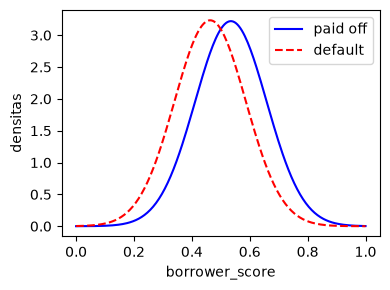

In [8]:
from scipy import stats
stats_bs = loan_data.groupby('outcome', observed=True)['borrower_score'].agg(['mean', 'std'])
print(stats_bs)

xs = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(xs, stats.norm.pdf(xs, *stats_bs.loc['paid off']), color='blue', label='paid off')
ax.plot(xs, stats.norm.pdf(xs, *stats_bs.loc['default']), color='red', linestyle='--', label='default')
ax.set_xlabel('borrower_score')
ax.set_ylabel('densitas')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretasi:** Rata-rata `borrower_score` pada pinjaman *default* adalah 0,463, sedangkan pada pinjaman *paid off* 0,535. Simpangan baku keduanya hampir sama (sekitar 0,123). Kurva normal kedua kelas sangat tumpang tindih, tetapi kurva *paid off* bergeser ke kanan. Dalam Gaussian Naive Bayes, rasio kedua densitas di titik $x$ inilah yang menggantikan $P(X_j \mid Y)$: skor di bawah sekitar 0,5 lebih "mendukung" *default*, skor di atasnya lebih mendukung *paid off*. Tumpang tindih yang besar menunjukkan bahwa satu prediktor saja tidak cukup untuk memisahkan kelas.

## 5.2 Discriminant Analysis
### Covariance Matrix dan Fisher's Linear Discriminant
**Teori:** *Discriminant analysis* adalah salah satu pengklasifikasi statistik tertua (R.A. Fisher, 1936). Varian yang paling umum adalah **Linear Discriminant Analysis (LDA)**.

**Kovarians.** Kovarians mengukur sejauh mana dua variabel bergerak bersama:
$$s_{x,z} = \frac{\sum_{i=1}^n (x_i - \bar{x})(z_i - \bar{z})}{n-1}$$
Untuk banyak variabel, kovarians disusun menjadi **covariance matrix** $\hat\Sigma$ yang diagonalnya berisi varians setiap variabel.

**Fisher's linear discriminant.** Misalkan ada dua prediktor numerik $x, z$ dan outcome biner $y$. LDA mencari kombinasi linear $w_x x + w_z z$ yang **memaksimalkan rasio** antara:
- **jarak antar kelas** (*between sum of squares*, $SS_{between}$): seberapa jauh rata-rata kedua kelas setelah diproyeksikan;
- **variasi di dalam kelas** (*within sum of squares*, $SS_{within}$): seberapa menyebar data di dalam masing-masing kelas.

$$\max_w \frac{SS_{between}}{SS_{within}}$$

Proyeksi terbaik adalah proyeksi yang membuat kedua kelompok terpisah sejauh mungkin dan masing-masing serapat mungkin. Solusinya proporsional dengan $\hat\Sigma^{-1}(\bar{x}_1 - \bar{x}_0)$, yaitu selisih vektor rata-rata yang "diputihkan" (*whitened*) dengan *pooled covariance matrix*.

**Asumsi:** prediktor berdistribusi normal multivariat dengan matriks kovarians yang **sama** di setiap kelas. Jika kovariansnya berbeda per kelas, gunakan **Quadratic Discriminant Analysis (QDA)** yang menghasilkan batas keputusan kuadratik.

**Kegunaan lain:** LDA juga dipakai untuk **reduksi dimensi** (bobot discriminant menunjukkan prediktor mana yang paling memisahkan kelas) dan untuk menghasilkan fitur bagi model lain.

### A Simple Example
**Data:** `loan3000` (3.000 pinjaman) dengan dua prediktor:
- `borrower_score`: skor kelayakan kredit peminjam (0–1, makin tinggi makin baik);
- `payment_inc_ratio`: rasio cicilan terhadap pendapatan.

In [9]:
loan3000 = pd.read_csv(LOAN3000_CSV)
loan3000.outcome = loan3000.outcome.astype('category')

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)
print(pd.DataFrame(loan_lda.scalings_, index=X.columns))

                          0
borrower_score     7.178232
payment_inc_ratio -0.099709


In [10]:
pred = pd.DataFrame(loan_lda.predict_proba(loan3000[predictors]),
                    columns=loan_lda.classes_)
print(pred.head())

    default  paid off
0  0.553591  0.446409
1  0.559004  0.440996
2  0.272576  0.727424
3  0.506270  0.493730
4  0.610035  0.389965


**Interpretasi:** Bobot discriminant (`scalings_`) adalah **7,18** untuk `borrower_score` dan **-0,0997** untuk `payment_inc_ratio`. Arah "menuju *paid off*" (kelas kedua) ditandai oleh `borrower_score` tinggi dan `payment_inc_ratio` rendah. Besarnya bobot tidak bisa langsung dibandingkan karena skala variabelnya berbeda: `borrower_score` berada di rentang 0–1, sedangkan `payment_inc_ratio` di rentang 0–20-an. Kenaikan `payment_inc_ratio` sebesar 1 unit setara dengan penurunan skor sekitar 0,014. Probabilitas prediksi lima record pertama berkisar dari 0,27 hingga 0,61 untuk *default*. Record ke-3 (0,273) cukup yakin *paid off*, sedangkan record ke-4 (0,506) praktis berada di batas keputusan. Angka-angka ini sama dengan buku.

### Figure 5.1 — Batas Keputusan LDA
**Teori:** Batas keputusan LDA adalah **garis lurus** (atau *hyperplane* pada dimensi lebih tinggi) yang tegak lurus terhadap arah discriminant dan melewati titik tengah rata-rata kedua kelas (dengan prior seimbang). Titik di satu sisi garis diprediksi *default*, sedangkan titik di sisi lain diprediksi *paid off*. Makin jauh sebuah titik dari garis, makin yakin prediksinya. Warna titik pada plot menunjukkan probabilitas *default*.

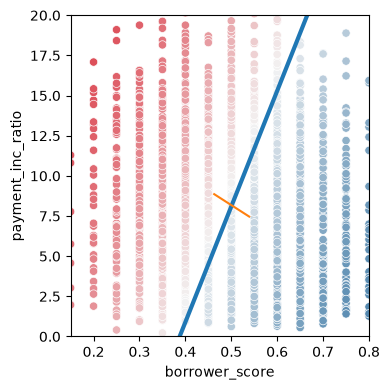

In [11]:
# Gunakan scalings dan pusat rata-rata kelas untuk menentukan garis batas keputusan
center = np.mean(loan_lda.means_, axis=0)
slope = - loan_lda.scalings_[0] / loan_lda.scalings_[1]
intercept = center[1] - center[0] * slope

# borrower_score pada payment_inc_ratio = 0 dan 20
x_0 = (0 - intercept) / slope
x_20 = (20 - intercept) / slope

lda_df = pd.concat([loan3000, pred['default']], axis=1)

fig, ax = plt.subplots(figsize=(4, 4))
g = sns.scatterplot(x='borrower_score', y='payment_inc_ratio',
                    hue='default', data=lda_df,
                    palette=sns.diverging_palette(240, 10, n=9, as_cmap=True),
                    ax=ax, legend=False)

ax.set_ylim(0, 20)
ax.set_xlim(0.15, 0.8)
ax.plot((x_0[0], x_20[0]), (0, 20), linewidth=3)
ax.plot(*loan_lda.means_.transpose())

plt.tight_layout()
plt.show()

**Interpretasi:** Garis biru tebal adalah batas keputusan LDA. Titik merah (probabilitas *default* tinggi) berada di kiri-atas, yaitu `borrower_score` rendah dan `payment_inc_ratio` tinggi. Titik biru (*paid off*) berada di kanan-bawah. Garisnya miring ke kanan: makin tinggi rasio cicilan terhadap pendapatan, makin tinggi `borrower_score` yang dibutuhkan agar pinjaman diprediksi lunas. Warna titik memudar secara bertahap ketika mendekati garis, sesuai dengan probabilitas yang mendekati 0,5. Garis oranye pendek menghubungkan rata-rata kedua kelas (centroid). Batas keputusan memotong garis ini di titik tengahnya dan tegak lurus terhadap arah discriminant (dalam metrik kovarians).

## 5.3 Logistic Regression
### Logistic Response Function and Logit
**Teori:** Logistic regression mirip dengan regresi linear, tetapi outcome-nya **biner**. Model ini bersifat **struktural** (berbasis persamaan), bukan berbasis data seperti KNN atau Naive Bayes. Karena cepat dihitung dan mudah ditafsirkan, logistic regression sangat populer untuk *scoring*.

Kita tidak bisa langsung memodelkan $p = P(Y=1)$ sebagai fungsi linear, karena hasilnya bisa keluar dari rentang $[0,1]$. Solusinya adalah transformasi bertahap:

1. **Logistic response function** (fungsi *sigmoid*) memetakan bilangan real apa pun ke $(0,1)$:
$$p = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \cdots + \beta_q x_q)}}$$
2. **Odds**, rasio "sukses" terhadap "gagal": $\text{Odds}(Y=1) = \dfrac{p}{1-p}$, dengan rentang $(0, \infty)$. Contohnya, odds 3 berarti peluang sukses 3:1, atau $p = 0{,}75$.
3. **Log-odds / logit** dengan rentang $(-\infty, \infty)$, yang dimodelkan secara linear:
$$\log(\text{Odds}(Y=1)) = \text{logit}(p) = \beta_0 + \beta_1 x_1 + \cdots + \beta_q x_q$$

Fungsi **logit** memetakan probabilitas $p \in (0,1)$ ke garis bilangan real. Fungsi ini adalah *link function* dalam logistic regression. Setelah model memprediksi log-odds, invers logit (sigmoid) mengembalikannya menjadi probabilitas, lalu *cutoff* dipakai untuk menentukan kelas.

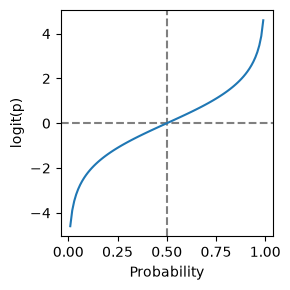

In [12]:
p = np.arange(0.01, 1, 0.01)
df = pd.DataFrame({
    'p': p,
    'logit': np.log(p / (1 - p)),
    'odds': p / (1 - p),
})

fig, ax = plt.subplots(figsize=(3, 3))
ax.axhline(0, color='grey', linestyle='--')
ax.axvline(0.5, color='grey', linestyle='--')
ax.plot(df['p'], df['logit'])
ax.set_xlabel('Probability')
ax.set_ylabel('logit(p)')

plt.tight_layout()
plt.show()

**Interpretasi:** Plot menunjukkan bahwa logit memetakan probabilitas 0,01–0,99 ke rentang sekitar -4,6 hingga +4,6. Pada $p = 0{,}5$, logit = 0 (perpotongan garis putus-putus). Kurvanya hampir linear di sekitar 0,5 dan menjadi sangat curam mendekati 0 dan 1. Karena itu perubahan kecil probabilitas di ujung-ujung rentang setara dengan perubahan log-odds yang besar. Sifat inilah yang memungkinkan model linear pada skala logit tidak pernah menghasilkan probabilitas di luar (0,1).

### Logistic Regression and the GLM
**Teori:** Logistic regression adalah kasus khusus dari **Generalized Linear Model (GLM)**. GLM memiliki dua komponen utama:
- **Probability family / distribusi**: distribusi outcome. Untuk outcome biner dipakai **binomial**.
- **Link function**: fungsi yang menghubungkan respons dengan prediktor linear. Untuk logistic regression link-nya adalah **logit**.

Anggota GLM lain antara lain regresi Poisson (data hitungan, link log), regresi gamma (waktu tunggu), dan regresi linear biasa (family Gaussian, link identitas).

**Implementasi di Python:**
- `sklearn.linear_model.LogisticRegression` khusus untuk klasifikasi. Model ini secara default memakai **regularisasi L2**. Agar setara dengan logistic regression klasik tanpa penalti, buku memakai `C=1e42` (penalti praktis nol).
- `statsmodels` (`sm.GLM` dengan `family=Binomial()`) memberi ringkasan statistik lengkap seperti *standard error*, *z-value*, dan *p-value*.

**Penyesuaian versi:** di scikit-learn 1.9 argumen `penalty` sudah *deprecated* (L2 adalah default), sehingga dihilangkan dari kode. Hasilnya tetap sama dengan kode buku.

**Data:** `loan_data` dengan prediktor `payment_inc_ratio`, `purpose_`, `home_`, `emp_len_`, dan `borrower_score`. Variabel kategorikal diubah menjadi dummy dengan `drop_first=True` (*reference coding*, $k-1$ dummy) agar tidak terjadi multikolinearitas sempurna.

In [13]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'borrower_score']
outcome = 'outcome'
X = pd.get_dummies(loan_data[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = loan_data[outcome]

# C sangat besar = (praktis) tanpa regularisasi; penalty default = 'l2'
logit_reg = LogisticRegression(C=1e42, solver='liblinear')
logit_reg.fit(X, y)

print('intercept ', logit_reg.intercept_[0])
print('classes', logit_reg.classes_)
pd.DataFrame({'coeff': logit_reg.coef_[0]},
             index=X.columns)

intercept  -1.638088683407208
classes ['default' 'paid off']


,coeff
payment_inc_ratio,-0.079728
borrower_score,4.611037
debt_consolidation,-0.249342
home_improvement,-0.407614
major_purchase,-0.229376
medical,-0.510087
other,-0.620534
small_business,-1.215662
OWN,-0.048453
RENT,-0.157355


Perhatikan bahwa scikit-learn mengurutkan kelas secara alfabetis (`['default', 'paid off']`) dan memodelkan **kelas kedua** (`paid off`) sebagai kelas "positif". Karena itu tanda intercept dan koefisien di sini **terbalik** dibanding model R di buku, yang memodelkan peluang *default*. Kategori referensi (yang dibuang oleh `drop_first`) dapat dilihat di bawah ini. Kategori pertama setiap variabel menjadi baseline.

In [14]:
print(loan_data['purpose_'].cat.categories)
print(loan_data['home_'].cat.categories)
print(loan_data['emp_len_'].cat.categories)

Index(['credit_card', 'debt_consolidation', 'home_improvement',
       'major_purchase', 'medical', 'other', 'small_business'],
      dtype='str')
Index(['MORTGAGE', 'OWN', 'RENT'], dtype='str')
Index([' < 1 Year', ' > 1 Year'], dtype='str')


_Tidak ada di buku:_ jika outcome bersifat ordinal, gunakan `OrdinalEncoder` untuk mengganti kategori dengan angka. Di bawah ini 'paid off' menjadi 0 dan 'default' menjadi 1, sehingga kelas positif adalah *default* dan tanda koefisien kembali sama dengan model R di buku.

In [15]:
enc = OrdinalEncoder(categories=[['paid off', 'default']])
y_enc = enc.fit_transform(loan_data[[outcome]]).ravel()

logit_reg_enc = LogisticRegression(C=1e42, solver='liblinear')
logit_reg_enc.fit(X, y_enc)

print('intercept ', logit_reg_enc.intercept_[0])
print('classes', logit_reg_enc.classes_)
pd.DataFrame({'coeff': logit_reg_enc.coef_[0]},
             index=X.columns)

intercept 

 1.6380885435754573
classes [0. 1.]


,coeff
payment_inc_ratio,0.079728
borrower_score,-4.611037
debt_consolidation,0.249342
home_improvement,0.407614
major_purchase,0.229376
medical,0.510087
other,0.620534
small_business,1.215662
OWN,0.048453
RENT,0.157355


**Interpretasi:** Model scikit-learn memodelkan kelas positif `paid off` sehingga intercept-nya **-1,638**. Koefisien `borrower_score` = **+4,61**, artinya skor lebih tinggi meningkatkan peluang lunas, dan `payment_inc_ratio` = **-0,080**, artinya rasio cicilan lebih tinggi menurunkan peluang lunas. Semua kategori `purpose_` bernilai negatif terhadap baseline `credit_card`, dengan `small_business` paling ekstrem (-1,216). Setelah outcome di-*encode* dengan `OrdinalEncoder` (default = 1), semua tanda **berbalik**: intercept +1,638, `small_business` +1,216, `borrower_score` -4,61. Nilai-nilai ini cocok dengan model R di buku (intercept 1,638; `borrower_score` -4,612; `small_business` 1,215). Kategori referensi adalah `credit_card` (purpose), `MORTGAGE` (home), dan `< 1 Year` (lama kerja).

### Predicted Values from Logistic Regression
**Teori:** Model logistic regression memprediksi **log-odds** $\hat{Y} = \log(\text{Odds}(Y=1))$. Probabilitas didapat lewat invers logit:
$$\hat{p} = \frac{1}{1 + e^{-\hat{Y}}}$$
Di scikit-learn, `predict_log_proba` mengembalikan $\log(\hat p)$ (logaritma probabilitas, **bukan** log-odds), `predict_proba` mengembalikan probabilitas, dan `predict` mengembalikan kelas dengan *cutoff* 0,5.

In [16]:
pred = pd.DataFrame(logit_reg.predict_log_proba(X),
                    columns=logit_reg.classes_)
print(pred.describe())

            default      paid off
count  45342.000000  45342.000000
mean      -0.757850     -0.760423
std        0.378032      0.390419
min       -2.768873     -3.538865
25%       -0.985728     -0.977164
50%       -0.697366     -0.688946
75%       -0.472209     -0.467076
max       -0.029476     -0.064787


In [17]:
pred = pd.DataFrame(logit_reg.predict_proba(X),
                    columns=logit_reg.classes_)
print(pred.describe())

            default      paid off
count  45342.000000  45342.000000
mean       0.500001      0.499999
std        0.167336      0.167336
min        0.062733      0.029046
25%        0.373167      0.376377
50%        0.497895      0.502105
75%        0.623623      0.626833
max        0.970954      0.937267


**Interpretasi:** Output `predict_log_proba` adalah $\log(\hat p)$, sehingga semuanya negatif: median sekitar -0,70 (≈ log 0,5) dan minimum -2,77 untuk *default*. Setelah dikonversi menjadi probabilitas, rata-rata P(default) = **0,500**. Ini wajar karena data diseimbangkan 50:50 dan logistic regression (MLE dengan intercept) selalu menghasilkan rata-rata prediksi sama dengan proporsi kelas aktual. Probabilitas *default* berkisar dari **0,063** hingga **0,971** dengan kuartil 0,373–0,624. Artinya sebagian besar prediksi berada di zona "tidak terlalu yakin" sekitar 0,5, yang menandakan prediktor hanya memisahkan kelas secara moderat.

### Interpreting the Coefficients and Odds Ratios
**Teori:** Keunggulan logistic regression adalah koefisiennya mudah ditafsirkan melalui **odds ratio**. Untuk prediktor biner $X$:
$$\text{odds ratio} = \frac{\text{Odds}(Y=1 \mid X=1)}{\text{Odds}(Y=1 \mid X=0)}$$
Odds ratio 2 berarti odds $Y=1$ dua kali lebih besar ketika $X=1$ dibanding $X=0$.

Koefisien $\beta_j$ adalah **log odds ratio**, sehingga $\exp(\beta_j)$ adalah odds ratio. Contoh dari buku: koefisien `purpose_small_business` (model R, terhadap *default*) kira-kira 1,21, sehingga $\exp(1{,}21) \approx 3{,}4$. Artinya pinjaman usaha kecil memiliki odds *default* sekitar 3,4 kali lebih besar dibanding pinjaman referensi (*credit card*).

Untuk prediktor numerik, $\exp(\beta_j)$ adalah perubahan multiplikatif odds untuk kenaikan 1 unit $X_j$, dengan prediktor lain dianggap tetap. Odds ratio dipakai karena lebih mudah dikerjakan secara matematis daripada rasio probabilitas, dan secara geometris hubungan log-odds dengan odds bersifat eksponensial (lihat plot).

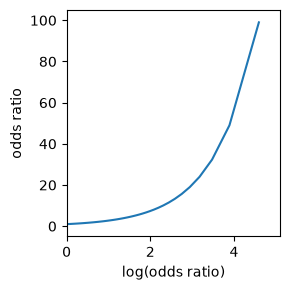

In [18]:
fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(df['logit'], df['odds'])
ax.set_xlabel('log(odds ratio)')
ax.set_ylabel('odds ratio')
ax.set_xlim(0, 5.1)
ax.set_ylim(-5, 105)

plt.tight_layout()
plt.show()

In [19]:
# Tambahan: odds ratio terhadap DEFAULT (dari model logit_reg_enc, kelas positif = default)
odds_ratio = pd.DataFrame({'coeff': logit_reg_enc.coef_[0],
                           'odds_ratio': np.exp(logit_reg_enc.coef_[0])},
                          index=X.columns)
print(odds_ratio.round(3))

                    coeff  odds_ratio
payment_inc_ratio   0.080       1.083
borrower_score     -4.611       0.010
debt_consolidation  0.249       1.283
home_improvement    0.408       1.503
major_purchase      0.229       1.258
medical             0.510       1.665
other               0.621       1.860
small_business      1.216       3.373
OWN                 0.048       1.050
RENT                0.157       1.170
 > 1 Year          -0.357       0.699


**Interpretasi:** Kurva menunjukkan hubungan **eksponensial** antara log odds ratio dan odds ratio. Log odds ratio 1 setara dengan odds ratio sekitar 2,7, sedangkan log odds ratio 4,6 sudah setara dengan odds ratio sekitar 100. Tabel odds ratio terhadap *default* memperlihatkan: `small_business` memiliki odds ratio **3,37**, artinya odds default pinjaman usaha kecil 3,4 kali odds pinjaman kartu kredit (sesuai contoh di buku). `other` (1,86) dan `medical` (1,67) juga berisiko lebih tinggi. Penyewa rumah (`RENT`) memiliki odds 1,17 kali dibanding pemilik ber-MORTGAGE. Lama kerja > 1 tahun menurunkan odds menjadi 0,70 kali. Setiap kenaikan 1 unit `payment_inc_ratio` mengalikan odds default dengan 1,083 (naik 8,3%). Odds ratio `borrower_score` 0,010 berlaku per kenaikan **1 unit penuh** (seluruh rentang skor). Untuk kenaikan 0,1, odds ratio-nya $e^{-0{,}461} \approx 0{,}63$.

### Linear and Logistic Regression: Similarities and Differences
**Teori:** Keduanya mengasumsikan hubungan linear antara prediktor dan (transformasi) respons. Struktur modelnya pun serupa: variabel dummy, interaksi, dan *spline* bisa dipakai di keduanya. Perbedaannya:

| Aspek | Linear regression | Logistic regression |
|---|---|---|
| Fitting | *Least squares* (solusi tertutup) | **Maximum Likelihood Estimation (MLE)** secara iteratif (misalnya *Fisher scoring* / IRLS) |
| Ukuran kecocokan | RSS, $R^2$, RMSE | **Deviance** $= -2\log(\text{likelihood})$, AIC |
| Residual | $y - \hat{y}$ | *deviance residual* / *Pearson residual* |

**MLE** mencari parameter $\hat\beta$ yang **paling mungkin** menghasilkan data yang teramati, yaitu yang memaksimalkan likelihood $\prod_i \hat{p}_i^{y_i}(1-\hat{p}_i)^{1-y_i}$. Makin kecil *deviance*, makin cocok modelnya.

### Assessing the Model
**Teori:** Kualitas logistic regression dinilai dengan:
- **Akurasi klasifikasi** pada data *holdout* (dibahas di 5.4);
- **Signifikansi koefisien**: *standard error*, *z-value*, dan *p-value*, yang ditafsirkan seperti pada regresi linear. *P-value* sebaiknya dipakai sebagai **indikator relatif pentingnya variabel**, bukan uji formal yang kaku;
- **Deviance / AIC** untuk membandingkan model (misalnya dalam *stepwise selection*);
- **Partial residual plot** untuk mendeteksi hubungan non-linear.

Untuk perbandingan, di bawah ini model yang sama di-*fit* sebagai GLM menggunakan *statsmodels*. Metode ini membutuhkan outcome dalam bentuk angka (1 = default).

In [20]:
# GLM (generalized linear model) dengan family binomial = logistic regression
y_numbers = [1 if yi == 'default' else 0 for yi in y]
logit_reg_sm = sm.GLM(y_numbers, X.assign(const=1),
                      family=sm.families.Binomial())
logit_result = logit_reg_sm.fit()
print(logit_result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Sat, 24 Oct 2026   Deviance:                       57515.
Time:                        23:24:05   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
payment_inc_ratio      0.0797      0

**Interpretasi:** GLM *statsmodels* memberikan koefisien yang **sama** dengan scikit-learn versi *encoded* (misalnya `borrower_score` -4,6126, `small_business` 1,2153, intercept 1,6381), ditambah inferensi statistik. Hampir semua koefisien sangat signifikan ($|z|$ besar, p < 0,001). `borrower_score` (z = -55,2) dan `payment_inc_ratio` (z = 32,1) adalah prediktor terkuat. Satu-satunya yang **tidak signifikan** adalah `OWN` (p = 0,204): setelah variabel lain dikontrol, pemilik rumah tanpa cicilan tidak berbeda nyata dari baseline MORTGAGE. *Deviance* model = **57.515** dengan log-likelihood -28.757. Model konvergen dalam 4 iterasi IRLS (*iteratively reweighted least squares*, cara statsmodels menjalankan MLE).

**Teori (spline dalam GLM):** Seperti pada regresi linear (Chapter 4), prediktor numerik dapat dimodelkan secara **non-linear** dengan *spline*. Fungsi `bs(x, df=k)` membentuk basis *B-spline* sehingga log-odds dapat "melengkung" mengikuti data. Di sini `payment_inc_ratio` diberi 8 derajat kebebasan dan `borrower_score` 3 derajat kebebasan.

Pada formula *statsmodels* dengan outcome kategorikal `['default', 'paid off']`, kategori **pertama** (`default`) dimodelkan sebagai "sukses". Jadi koefisien positif berarti peluang *default* naik.

In [21]:
formula = ('outcome ~ bs(payment_inc_ratio, df=8) + purpose_ + ' +
           'home_ + emp_len_ + bs(borrower_score, df=3)')
model = smf.glm(formula=formula, data=loan_data, family=sm.families.Binomial())
results = model.fit()
print(results.summary())

                             Generalized Linear Model Regression Results                             
Dep. Variable:     ['outcome[default]', 'outcome[paid off]']   No. Observations:                45342
Model:                                                   GLM   Df Residuals:                    45321
Model Family:                                       Binomial   Df Model:                           20
Link Function:                                         Logit   Scale:                          1.0000
Method:                                                 IRLS   Log-Likelihood:                -28731.
Date:                                       Sat, 24 Oct 2026   Deviance:                       57462.
Time:                                               23:24:06   Pearson chi2:                 4.54e+04
No. Iterations:                                            6   Pseudo R-squ. (CS):             0.1122
Covariance Type:                                   nonrobust                      

**Teori (partial residual plot):** Plot ini menunjukkan **kontribusi satu prediktor** terhadap log-odds (garis), ditumpangkan pada residual (titik). Jika garis kontribusi melengkung, hubungan prediktor tersebut tidak linear. Pada logistic regression, residualnya hanya punya dua "pita" nilai karena outcome biner, sehingga plot ini lebih sulit dibaca dibanding pada regresi linear.

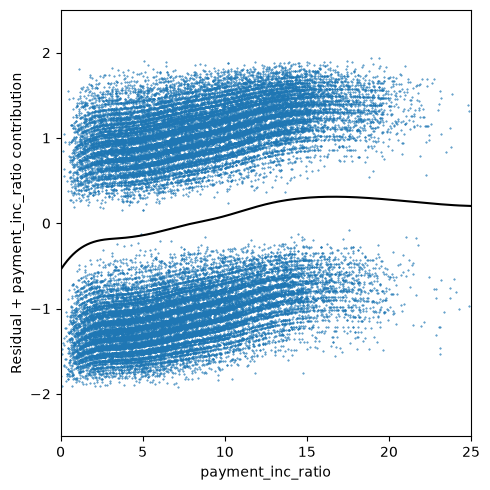

In [22]:
def partialResidualPlot(model, df, outcome, feature, fig, ax):
    y_actual = [0 if s == 'default' else 1 for s in df[outcome]]
    y_pred = model.predict(df)
    org_params = model.params.copy()
    zero_params = model.params.copy()
    # set parameter model untuk fitur lain menjadi 0
    for i, name in enumerate(zero_params.index):
        if feature in name:
            continue
        zero_params.iloc[i] = 0.0
    model.initialize(model.model, zero_params)
    feature_prediction = model.predict(df)
    ypartial = -np.log(1/feature_prediction - 1)
    ypartial = ypartial - np.mean(ypartial)
    model.initialize(model.model, org_params)
    results = pd.DataFrame({
        'feature': df[feature],
        'residual': -2 * (y_actual - y_pred),
        'ypartial': ypartial/ 2,
    })
    results = results.sort_values(by=['feature'])

    ax.scatter(results.feature, results.residual, marker=".", s=72./fig.dpi)
    ax.plot(results.feature, results.ypartial, color='black')
    ax.set_xlabel(feature)
    ax.set_ylabel(f'Residual + {feature} contribution')
    return ax

fig, ax = plt.subplots(figsize=(5, 5))
partialResidualPlot(results, loan_data, 'outcome', 'payment_inc_ratio', fig, ax)
ax.set_xlim(0, 25)
ax.set_ylim(-2.5, 2.5)

plt.tight_layout()
plt.show()

**Interpretasi:** Model dengan *spline* sedikit lebih baik: *deviance* turun dari 57.515 menjadi **57.462** (selisih sekitar 53) dengan tambahan 9 derajat kebebasan. Koefisien variabel kategorikal hampir tidak berubah (misalnya `small_business` 1,225). Basis *spline* `payment_inc_ratio` bernilai positif dan cenderung naik hingga basis ke-6 (2,84). Dua basis terakhir memiliki standard error besar (1,23 dan 6,39) karena data di nilai `payment_inc_ratio` ekstrem sangat sedikit. Pada partial residual plot, garis kontribusi `payment_inc_ratio` naik tajam dari 0 sampai sekitar 2, naik landai hingga sekitar 15, lalu **mendatar bahkan sedikit turun** di atas 17. Ini adalah indikasi non-linearitas yang tidak tertangkap model linear, walaupun di ujung kanan (data sedikit) bentuknya tidak dapat dipercaya. Titik-titik residual membentuk dua pita (atas dan bawah) karena outcome hanya bernilai 0/1.

## 5.4 Evaluating Classification Models
### Confusion Matrix
**Teori:** Metrik paling sederhana adalah **akurasi**, yaitu persentase prediksi yang benar:
$$\text{accuracy} = \frac{\sum \text{TruePositive} + \sum \text{TrueNegative}}{\text{Sample Size}}$$

**Confusion matrix** merinci hasil klasifikasi menjadi empat sel (dengan *default* sebagai kelas positif):

| | Prediksi = default | Prediksi = paid off |
|---|---|---|
| **Aktual = default** | True Positive (TP) | False Negative (FN) |
| **Aktual = paid off** | False Positive (FP) | True Negative (TN) |

Diagonal utama berisi prediksi benar, sedangkan sel di luar diagonal berisi kesalahan. Kesalahan **FN** (gagal mendeteksi default) dan **FP** (salah menuduh default) sering memiliki biaya yang sangat berbeda, sehingga akurasi saja tidak cukup.

*Catatan:* `sklearn.metrics.confusion_matrix` menyusun baris = aktual dan kolom = prediksi, dengan urutan kelas alfabetis (`default`, `paid off`). Pada data ini urutan tersebut kebetulan sama dengan tabel di atas.

In [23]:
# Confusion matrix manual
pred = logit_reg.predict(X)
pred_y = logit_reg.predict(X) == 'default'
true_y = y == 'default'
true_pos = true_y & pred_y
true_neg = ~true_y & ~pred_y
false_pos = ~true_y & pred_y
false_neg = true_y & ~pred_y

conf_mat = pd.DataFrame([[np.sum(true_pos), np.sum(false_neg)], [np.sum(false_pos), np.sum(true_neg)]],
                       index=['Y = default', 'Y = paid off'],
                       columns=['Yhat = default', 'Yhat = paid off'])
print(conf_mat)

              Yhat = default  Yhat = paid off
Y = default            14336             8335
Y = paid off            8148            14523


In [24]:
print(confusion_matrix(y, logit_reg.predict(X)))

[[14336  8335]
 [ 8148 14523]]


Paket _dmba_ menyediakan fungsi `classificationSummary` yang mencetak confusion matrix sekaligus akurasi.

In [25]:
classificationSummary(y, logit_reg.predict(X),
                      class_names=logit_reg.classes_)

Confusion Matrix (Accuracy 0.6365)

         Prediction
  Actual  default paid off
 default    14336     8335
paid off     8148    14523


**Interpretasi:** Dari 22.671 pinjaman *default*, **14.336** terdeteksi dengan benar (TP) dan **8.335** terlewat (FN). Dari 22.671 pinjaman lunas, **14.523** benar (TN) dan **8.148** salah dituduh default (FP). Akurasi = (14.336 + 14.523) / 45.342 = **0,6365**. Ketiga cara (manual, `confusion_matrix`, `classificationSummary`) memberi angka yang sama. Kesalahan FN dan FP hampir seimbang karena data 50:50 dan *cutoff* 0,5. Akurasi 63,7% cukup moderat; prediktor yang tersedia hanya memisahkan kelas sebagian. Angka ini dihitung pada data latih, sehingga untuk penilaian yang jujur seharusnya dipakai data *holdout*.

### The Rare Class Problem
**Teori:** Dalam banyak aplikasi, kelas yang diminati adalah kelas **langka** (*rare class*), misalnya transaksi *fraud*, klaim asuransi palsu, atau pembeli dari sebuah kampanye pemasaran (bisa di bawah 1%). Kelas langka ini biasanya diberi label 1 (positif).

Masalahnya, pada data seperti itu model yang **selalu memprediksi kelas mayoritas** (misalnya "tidak fraud") bisa mencapai akurasi 99% tanpa berguna sama sekali. Model yang benar-benar menemukan sebagian fraud mungkin akurasinya lebih rendah, karena ikut salah menandai sebagian transaksi normal, tetapi nilai bisnisnya jauh lebih besar. Karena itu, untuk kelas langka kita membutuhkan metrik selain akurasi (precision, recall, ROC, lift) dan sering kali sengaja menerima lebih banyak *false positive* demi menangkap lebih banyak kasus positif.

### Precision, Recall, and Specificity
**Teori:** Metrik yang berfokus pada kelas positif:
- **Precision** (*positive predictive value*): dari semua yang diprediksi positif, berapa yang benar-benar positif?
$$\text{precision} = \frac{TP}{TP + FP}$$
- **Recall** (*sensitivity*, *true positive rate*): dari semua yang benar-benar positif, berapa yang berhasil terdeteksi?
$$\text{recall} = \frac{TP}{TP + FN}$$
- **Specificity** (*true negative rate*): dari semua yang benar-benar negatif, berapa yang benar diprediksi negatif?
$$\text{specificity} = \frac{TN}{TN + FP}$$

Biasanya ada *trade-off*: menurunkan *cutoff* menaikkan recall tetapi menurunkan precision dan specificity. **F1-score** adalah rata-rata harmonik precision dan recall: $F_1 = 2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$. Fungsi `precision_recall_fscore_support` dari scikit-learn mengembalikan precision, recall, F-score, dan *support* (jumlah record per kelas).

In [26]:
conf_mat = confusion_matrix(y, logit_reg.predict(X))
print('Precision', conf_mat[0, 0] / sum(conf_mat[:, 0]))
print('Recall', conf_mat[0, 0] / sum(conf_mat[0, :]))
print('Specificity', conf_mat[1, 1] / sum(conf_mat[1, :]))

Precision 0.6376089663760897
Recall 0.6323496978518812
Specificity 0.6405981209474659


In [27]:
precision_recall_fscore_support(y, logit_reg.predict(X),
                                labels=['default', 'paid off'])

(array([0.63760897, 0.63535742]),
 array([0.6323497 , 0.64059812]),
 array([0.63496844, 0.63796701]),
 array([22671, 22671]))

**Interpretasi:** **Precision = 0,638**: dari pinjaman yang diprediksi default, 63,8% benar-benar default. **Recall = 0,632**: model menangkap 63,2% dari semua default. **Specificity = 0,641**: 64,1% pinjaman lunas diprediksi dengan benar. `precision_recall_fscore_support` mengonfirmasi angka-angka ini. Elemen pertama setiap array adalah kelas *default*: precision 0,6376, recall 0,6323, F1 0,6350, dan support 22.671. Elemen kedua adalah kelas *paid off*; recall *paid off* (0,6406) sama dengan specificity untuk *default*. Ketiga metrik hampir sama karena data seimbang. Pada data tidak seimbang, angka-angka ini akan jauh berbeda.

### ROC Curve
**Teori:** Kurva **ROC** (*Receiver Operating Characteristics*, berasal dari analisis radar pada Perang Dunia II) menggambarkan *trade-off* antara **recall** (sumbu y) dan **specificity** (sumbu x) untuk **semua kemungkinan cutoff**. Cara membuatnya:
1. Urutkan record berdasarkan probabilitas prediksi kelas positif, dari tertinggi ke terendah.
2. Untuk setiap *cutoff*, hitung recall dan specificity.
3. Plot recall terhadap specificity. Sumbu x specificity digambar **dari 1 ke 0**, atau setara dengan *false positive rate* $= 1 - \text{specificity}$ dari 0 ke 1.

**Cara membaca:** garis diagonal adalah pengklasifikasi **acak**. Makin dekat kurva ke **sudut kiri atas** (recall tinggi sekaligus specificity tinggi), makin baik modelnya. Fungsi `roc_curve` di scikit-learn menghitung FPR, TPR, dan threshold yang dibutuhkan.

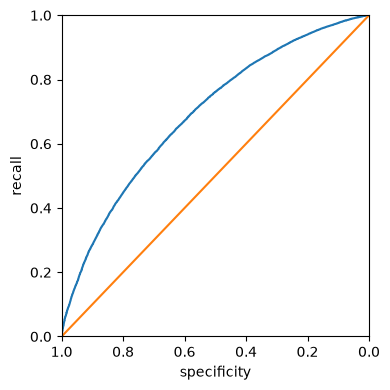

In [28]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.plot((1, 0), (0, 1))
ax.set_xlabel('specificity')
ax.set_ylabel('recall')

plt.tight_layout()
plt.show()

**Interpretasi:** Kurva ROC berada **di atas diagonal** (garis oranye, pengklasifikasi acak) di seluruh rentangnya, tetapi tidak terlalu dekat ke sudut kiri atas. Misalnya untuk mencapai recall sekitar 0,8, specificity harus turun ke kira-kira 0,45. Bentuk ini sesuai dengan akurasi 63,7%: model memang informatif, tetapi kemampuan pemisahnya hanya moderat. Di setiap titik kurva terlihat *trade-off* antara menangkap lebih banyak default dan salah menandai lebih banyak pinjaman baik.

### AUC
**Teori:** **AUC** (*Area Under the ROC Curve*) merangkum kurva ROC menjadi satu angka:
- AUC = 1: pengklasifikasi sempurna, yaitu ada *cutoff* yang memisahkan semua kelas dengan benar;
- AUC = 0,5: tidak lebih baik dari tebakan acak (kurva sama dengan diagonal);
- AUC < 0,5: lebih buruk dari acak, biasanya karena label terbalik.

Interpretasi probabilistik: AUC adalah **probabilitas bahwa sebuah record positif yang dipilih acak mendapat skor lebih tinggi daripada record negatif yang dipilih acak**. AUC dapat dihitung manual dengan integrasi numerik (jumlah recall × lebar langkah FPR) atau dengan `roc_auc_score`.

**Hati-hati:** AUC tidak bergantung pada *cutoff* sehingga tidak langsung mencerminkan biaya kesalahan pada *cutoff* yang dipakai. Pada kelas yang sangat langka, AUC bisa tampak baik walaupun precision di sekitar *cutoff* praktis sangat rendah.

In [29]:
print(np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity)))
print(roc_auc_score([1 if yi == 'default' else 0 for yi in y], logit_reg.predict_proba(X)[:, 0]))

0.691710795288669
0.6917108731135808


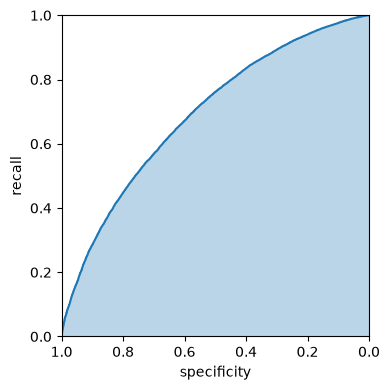

In [30]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:,0],
                                 pos_label='default')
roc_df = pd.DataFrame({'recall': tpr, 'specificity': 1 - fpr})

ax = roc_df.plot(x='specificity', y='recall', figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.set_xlabel('specificity')
ax.set_ylabel('recall')
ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretasi:** AUC hasil integrasi manual = **0,6917**, identik dengan `roc_auc_score` (0,6917) dan sama dengan nilai di buku (0,692). Interpretasinya: jika diambil satu pinjaman default dan satu pinjaman lunas secara acak, model memberi skor default lebih tinggi pada pinjaman default dengan peluang sekitar 69%. Nilai ini jauh di atas 0,5 (acak) tetapi jauh dari 1 (sempurna). Area berarsir pada plot adalah luas AUC tersebut.

### Lift
**Teori:** AUC menilai model pada **semua** *cutoff*. Namun dalam praktik (terutama untuk kelas langka) kita sering hanya bertindak pada sebagian kecil record dengan skor tertinggi, misalnya mengirim promosi ke 10% pelanggan teratas. **Lift** mengukur seberapa jauh model lebih efektif daripada pemilihan acak pada bagian teratas tersebut:
$$\text{lift}(\text{decile } d) = \frac{\text{proporsi kelas 1 di decile } d}{\text{proporsi kelas 1 secara keseluruhan}}$$

- **Lift chart (decile-wise):** record diurutkan berdasarkan probabilitas prediksi lalu dibagi menjadi 10 decile. Lift 2 pada decile pertama berarti 10% record teratas mengandung kelas positif dua kali lebih banyak daripada rata-rata.
- **Cumulative gains chart:** jumlah kumulatif kelas positif yang tertangkap terhadap jumlah record yang dipilih, dibandingkan dengan garis acak. Kurva *lift/gains* membantu memilih *cutoff* yang masuk akal secara bisnis.

Notebook resmi Python tidak memuat kode lift. Di bawah ini lift chart dibuat dengan fungsi `liftChart` dan `gainsChart` dari paket *dmba* (pendamping buku).

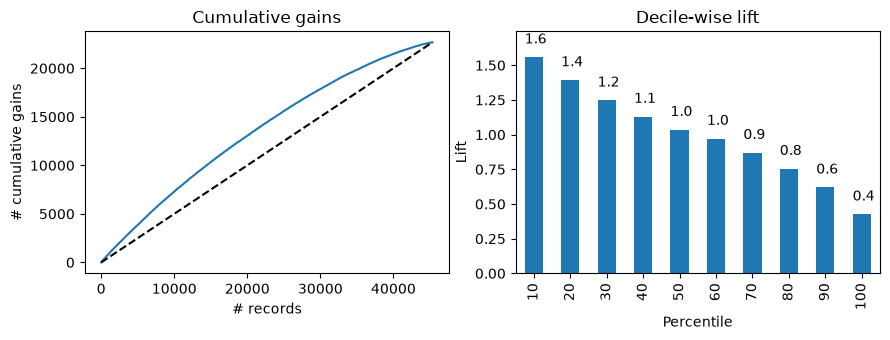

decile
1     1.558
2     1.393
3     1.247
4     1.130
5     1.035
6     0.971
7     0.869
8     0.754
9     0.619
10    0.426
Name: actual, dtype: float64


In [31]:
# Probabilitas default, diurutkan dari tertinggi ke terendah
prob_default = logit_reg.predict_proba(X)[:, 0]
lift_df = pd.DataFrame({'prob': prob_default,
                        'actual': (y == 'default').astype(int).values})
lift_df = lift_df.sort_values('prob', ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(9, 3.5))
gainsChart(lift_df.actual, ax=axes[0])
axes[0].set_title('Cumulative gains')
liftChart(lift_df.actual, title=False, ax=axes[1])
axes[1].set_title('Decile-wise lift')
plt.tight_layout()
plt.show()

# Tabel lift per decile
lift_df['decile'] = pd.qcut(lift_df.index, 10, labels=range(1, 11))
lift_table = lift_df.groupby('decile', observed=True)['actual'].mean() / lift_df.actual.mean()
print(lift_table.round(3))

**Interpretasi:** Kurva *cumulative gains* selalu berada di atas garis acak (putus-putus). Contohnya, dengan memilih 20.000 record berskor tertinggi (sekitar 44% data) tertangkap sekitar 13.000 default, sedangkan pemilihan acak hanya menghasilkan sekitar 10.000. Pada *decile-wise lift*, **10% teratas memiliki lift 1,56**: proporsi default di sana sekitar 78% (1,56 × 50%), dibanding 50% secara keseluruhan. Lift turun monoton ke 1,39, 1,25, dan seterusnya hingga **0,43** di decile terbawah (hanya sekitar 21% default). Pola menurun yang rapi menunjukkan bahwa ranking model konsisten. Lift tidak setinggi pada kasus kelas langka karena di sini kelas positif sudah 50% (lift maksimum yang mungkin hanya 2).

## 5.5 Strategies for Imbalanced Data
**Teori:** Data `loan_data` yang dipakai sejauh ini **sengaja diseimbangkan** (50% default). Data nyata Lending Club `full_train_set` jauh lebih tidak seimbang. Jika satu kelas sangat jarang, model cenderung "malas" dan memprediksi hampir semua record sebagai kelas mayoritas. Bagian ini membahas strategi untuk mengatasinya.

In [32]:
full_train_set = pd.read_csv(FULL_TRAIN_SET_CSV)
print(full_train_set.shape)

(119987, 19)


In [33]:
print('percentage of loans in default: ',
      100 * np.mean(full_train_set.outcome == 'default'))

percentage of loans in default:  18.894546909248504


### Undersampling
**Teori:** Jika data cukup banyak, salah satu solusi adalah **undersampling** (*downsampling*) kelas mayoritas: buang sebagian record kelas mayoritas secara acak sehingga kedua kelas lebih seimbang. Idenya, data kelas mayoritas banyak yang **redundan**, sehingga membuangnya hanya menghilangkan sedikit informasi. Model kemudian di-*fit* pada data yang lebih seimbang.

Untuk melihat masalahnya, kita mulai dengan model logistic regression pada **data penuh yang tidak seimbang**. Prediktornya adalah `payment_inc_ratio`, `purpose_`, `home_`, `emp_len_`, `dti`, `revol_bal`, dan `revol_util`.

In [34]:
predictors = ['payment_inc_ratio', 'purpose_', 'home_', 'emp_len_',
              'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'
X = pd.get_dummies(full_train_set[predictors], prefix='', prefix_sep='',
                   drop_first=True, dtype=int)
y = full_train_set[outcome]

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X, y)
print('percentage of loans predicted to default: ',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans predicted to default:  0.0


In [35]:
# rasio proporsi default sebenarnya terhadap proporsi default yang diprediksi
# (dijaga agar tidak membagi dengan nol jika model tidak memprediksi default sama sekali)
n_pred_default = np.sum(full_model.predict(X) == 'default')
print('jumlah pinjaman yang diprediksi default:', n_pred_default)
if n_pred_default > 0:
    print('rasio:', np.mean(full_train_set.outcome == 'default') /
                    np.mean(full_model.predict(X) == 'default'))

# Diagnostik tambahan: distribusi probabilitas default yang diprediksi
p_def_full = full_model.predict_proba(X)[:, list(full_model.classes_).index('default')]
print(f'rata-rata P(default) = {p_def_full.mean():.4f}, maksimum = {p_def_full.max():.4f}')

jumlah pinjaman yang diprediksi default: 0
rata-rata P(default) = 0.2132, maksimum = 0.4220


Kode Python resmi berhenti di sini. Versi R di buku melanjutkan dengan *downsampling* kelas *paid off* sampai sama banyak dengan *default*. Berikut adaptasinya dengan `RandomUnderSampler` dari *imbalanced-learn* (tambahan).

In [36]:
rus = RandomUnderSampler(random_state=1)
X_under, y_under = rus.fit_resample(X, y)
print('ukuran data setelah undersampling:', X_under.shape)
print(y_under.value_counts())

under_model = LogisticRegression(C=1e42, solver='liblinear')
under_model.fit(X_under, y_under)
print('percentage of loans predicted to default (undersampling): ',
      100 * np.mean(under_model.predict(X) == 'default'))

ukuran data setelah undersampling: (45342, 13)
outcome
default     22671
paid off    22671
Name: count, dtype: int64


percentage of loans predicted to default (undersampling):  42.580446215006624


**Interpretasi:** `full_train_set` berisi 119.987 pinjaman dan hanya **18,9%** di antaranya default. Logistic regression pada data penuh ini memprediksi **0%** pinjaman sebagai default: tidak ada satu pun record yang probabilitas default-nya melewati 0,5 (maksimum hanya sekitar 0,42, sedangkan rata-ratanya sekitar 0,21). Notebook resmi mendapat 0,0175% (21 pinjaman). Perbedaan kecil ini muncul karena optimisasi `liblinear` tanpa penalti pada fitur berskala sangat berbeda (`revol_bal` bernilai puluhan ribu), tetapi kesimpulannya sama: dengan *cutoff* 0,5, model praktis tidak berguna untuk mendeteksi default. Setelah **undersampling** kelas *paid off* menjadi 22.671 record (sama dengan jumlah default, total 45.342), model yang dilatih ulang memprediksi **42,6%** pinjaman sebagai default. Model kini jauh lebih sensitif, dengan konsekuensi lebih banyak *false positive*.

### Oversampling and Up/Down Weighting
**Teori:** Jika data kelas langka sedikit (misalnya hanya ratusan), membuang data mayoritas berarti kehilangan banyak informasi. Alternatifnya:
- **Oversampling** (*upsampling*): ambil sampel ulang **dengan pengembalian** (*bootstrap*) dari kelas langka sampai jumlahnya seimbang.
- **Up-weighting / down-weighting**: secara matematis setara dengan oversampling, tetapi tanpa menggandakan data. Setiap record diberi **bobot** dalam fungsi likelihood. Record kelas langka diberi bobot $w = 1/p_{\text{default}}$ (kebalikan proporsinya), sedangkan kelas mayoritas diberi bobot 1. Dengan begitu total bobot kedua kelas kira-kira seimbang.

Di scikit-learn bobot diberikan lewat argumen `sample_weight` pada `fit`. Alternatif yang setara adalah `class_weight='balanced'`. *Penyesuaian versi:* kode asli memberi bobot sebagai argumen posisi ketiga; di sini dipakai argumen bernama `sample_weight=` yang lebih aman.

In [37]:
default_wt = 1 / np.mean(full_train_set.outcome == 'default')
wt = [default_wt if outcome == 'default' else 1 for outcome in full_train_set.outcome]

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X, y, sample_weight=wt)
print('percentage of loans predicted to default (weighting): ',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans predicted to default (weighting):  61.43998933217766


**Interpretasi:** Bobot kelas default adalah $1/0{,}189 \approx 5{,}29$, sedangkan kelas lunas diberi bobot 1. Dengan *up-weighting*, model memprediksi **61,4%** pinjaman sebagai default (notebook resmi: 60,5%, buku versi R: sekitar 58%). Persentase ini lebih tinggi daripada hasil undersampling (42,6%). Bobot dan undersampling secara konsep setara, tetapi hasilnya berbeda di sini karena optimisasi `liblinear` dengan fitur berskala sangat berbeda tidak sepenuhnya stabil. Kedua cara sama-sama menggeser model dari "tidak pernah memprediksi default" menjadi model yang benar-benar menandai banyak pinjaman berisiko.

### Data Generation (SMOTE)
**Teori:** Variasi dari oversampling adalah **membangkitkan record baru** yang mirip, tetapi tidak identik, dengan record kelas langka. Pendekatan ini disebut *data augmentation*. Algoritma yang paling terkenal adalah **SMOTE** (*Synthetic Minority Oversampling Technique*):
1. Untuk sebuah record kelas langka $x_i$, cari $k$ tetangga terdekatnya (KNN) yang juga kelas langka.
2. Pilih satu tetangga $x_{nn}$ secara acak.
3. Buat record sintetis sebagai kombinasi acak keduanya: $x_{new} = x_i + \lambda (x_{nn} - x_i)$ dengan $\lambda \sim U(0,1)$.

Dengan cara ini record baru tersebar di "ruang antara" titik-titik kelas langka, sehingga mengurangi *overfitting* yang muncul ketika record yang sama hanya diduplikasi. Varian lainnya:
- **ADASYN** (*adaptive synthetic sampling*): membangkitkan lebih banyak sampel di daerah yang **sulit dipelajari**, yaitu titik minoritas yang dikelilingi banyak titik mayoritas;
- **Borderline-SMOTE**: hanya membangkitkan sampel di dekat **batas keputusan**.

Paket *imbalanced-learn* menyediakan semua algoritma ini.

In [38]:
X_resampled, y_resampled = SMOTE(random_state=1).fit_resample(X, y)
print('percentage of loans in default (SMOTE resampled): ',
      100 * np.mean(y_resampled == 'default'))

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X_resampled, y_resampled)
print('percentage of loans predicted to default (SMOTE): ',
      100 * np.mean(full_model.predict(X) == 'default'))


X_resampled, y_resampled = ADASYN(random_state=1).fit_resample(X, y)
print('percentage of loans in default (ADASYN resampled): ',
      100 * np.mean(y_resampled == 'default'))

full_model = LogisticRegression(C=1e42, solver='liblinear')
full_model.fit(X_resampled, y_resampled)
print('percentage of loans predicted to default (ADASYN): ',
      100 * np.mean(full_model.predict(X) == 'default'))

percentage of loans in default (SMOTE resampled):  50.0


percentage of loans predicted to default (SMOTE):  29.273171260219854


percentage of loans in default (ADASYN resampled):  48.56040383751355


percentage of loans predicted to default (ADASYN):  27.607990865677113


**Interpretasi:** SMOTE menyeimbangkan data persis menjadi **50%** default dengan membangkitkan record sintetis. Model yang dilatih pada data SMOTE memprediksi **29,3%** pinjaman (asli) sebagai default. ADASYN menghasilkan data dengan **48,6%** default, karena jumlah sampel sintetisnya ditentukan secara adaptif, dan model memprediksi **27,6%** sebagai default. Angka-angka ini hampir sama dengan notebook resmi (29,26% dan 27,40%). Kedua metode menghasilkan model yang lebih "moderat" daripada *weighting* (61,4%) dan undersampling (42,6%). Salah satu sebabnya, variabel dummy diinterpolasi SMOTE menjadi nilai pecahan yang tidak realistis, sehingga sinyal dari prediktor kategorikal sedikit kabur. Tidak ada metode yang otomatis terbaik; pilihan sebaiknya divalidasi pada data *holdout* dengan metrik yang relevan (recall, precision, atau biaya).

### Cost-Based Classification
**Teori:** Pada praktiknya, akurasi dan AUC adalah cara yang "kasar" untuk memilih *cutoff*. Sering kali kita bisa menaksir **nilai ekonomi** dari setiap hasil prediksi. Contoh pada pinjaman:
- biaya rata-rata pinjaman yang *default* = $C$ (kerugian pokok);
- keuntungan rata-rata pinjaman yang lunas = $R$ (pendapatan bunga).

Daripada sekadar memberi label default/lunas, lebih masuk akal menghitung **nilai harapan** (*expected return*) setiap pinjaman:
$$\text{Expected return} = P(Y=0)\times R + P(Y=1)\times(-C)$$
Pinjaman disetujui jika nilai harapannya positif. Dengan kata lain, *cutoff* optimal ditentukan oleh rasio biaya dan manfaat, bukan oleh angka 0,5. Jika menerima pinjaman yang default (FN) jauh lebih mahal daripada menolak pinjaman yang baik (FP), *cutoff* untuk menolak harus jauh lebih rendah.

Buku hanya membahas konsep ini tanpa kode. Di bawah ini ada ilustrasi sederhana (tambahan) dengan model *weighted* di atas dan nilai **asumsi** $R = 1$ dan $C = 4$ (satuan relatif). Kita mencari *cutoff* probabilitas default yang memaksimalkan total *expected profit* pada data latih.

cutoff optimal (prob. default) = 0.57
profit pada cutoff optimal    = 23,419
profit pada cutoff 0.5        = 19,547
profit jika semua disetujui   = 6,632


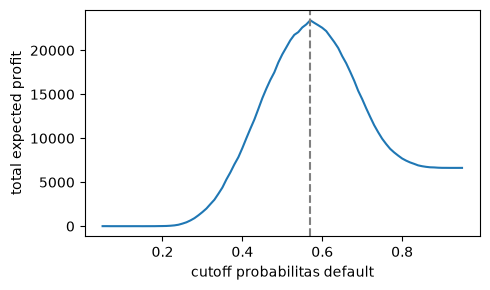

In [39]:
# Model berbobot (setara oversampling); probabilitas default per pinjaman
cost_model = LogisticRegression(C=1e42, solver='liblinear')
cost_model.fit(X, y, sample_weight=wt)
p_default = cost_model.predict_proba(X)[:, list(cost_model.classes_).index('default')]
is_default = (y == 'default').values

R, C = 1.0, 4.0   # asumsi: untung per pinjaman lunas, rugi per pinjaman default
cutoffs = np.linspace(0.05, 0.95, 91)
profit = []
for c in cutoffs:
    approve = p_default < c           # setujui jika prob. default di bawah cutoff
    profit.append(np.sum(approve & ~is_default) * R - np.sum(approve & is_default) * C)
profit = np.array(profit)
best = cutoffs[np.argmax(profit)]
print(f'cutoff optimal (prob. default) = {best:.2f}')
print(f'profit pada cutoff optimal    = {profit.max():,.0f}')
print(f'profit pada cutoff 0.5        = {profit[np.argmin(np.abs(cutoffs - 0.5))]:,.0f}')
print(f'profit jika semua disetujui   = {np.sum(~is_default) * R - np.sum(is_default) * C:,.0f}')

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(cutoffs, profit)
ax.axvline(best, color='grey', linestyle='--')
ax.set_xlabel('cutoff probabilitas default')
ax.set_ylabel('total expected profit')
plt.tight_layout()
plt.show()

**Interpretasi:** Dengan asumsi untung 1 per pinjaman lunas dan rugi 4 per pinjaman default, **menyetujui semua pinjaman** hanya menghasilkan total profit **6.632**. Memakai *cutoff* 0,5 pada model berbobot (menolak pinjaman dengan P(default) ≥ 0,5) menaikkan profit menjadi **19.547**. *Cutoff* optimal hasil pencarian adalah **0,57** dengan profit **23.419**, sekitar 20% lebih tinggi daripada *cutoff* standar. Kurva profit naik dari *cutoff* rendah (terlalu banyak pinjaman baik ditolak), mencapai puncak, lalu turun (terlalu banyak pinjaman berisiko disetujui). Secara teori, titik impas berada di P(default) aktual = R/(R+C) = 0,2. Karena probabilitas model berbobot "digelembungkan" oleh *up-weighting*, *cutoff* optimal pada skalanya menjadi sekitar 0,57. Ini menegaskan bahwa *cutoff* sebaiknya dipilih berdasarkan biaya, bukan dipatok 0,5. Dalam praktik pencarian *cutoff* harus dilakukan pada data *holdout*.

### Exploring the Predictions
**Teori:** Satu metrik seperti AUC tidak cukup untuk memahami **perilaku** model. Cara yang informatif adalah **memvisualisasikan batas keputusan** beberapa model pada data dua dimensi. Di sini empat model dibandingkan pada `loan3000` dengan dua prediktor (`borrower_score`, `payment_inc_ratio`):
- **Decision tree**: batas keputusan berbentuk "tangga" (aturan *if-then* yang membagi ruang menjadi persegi panjang);
- **LDA** dan **logistic regression**: batas keputusan berupa **garis lurus** (model linear);
- **GAM** (*Generalized Additive Model*): batas keputusan **mulus melengkung**, karena setiap prediktor dimodelkan dengan *spline*.

Visualisasi ini membantu menilai apakah perilaku model **masuk akal** secara domain. Contohnya, wajar jika batas `payment_inc_ratio` untuk default naik ketika `borrower_score` membaik. Perilaku di daerah dengan sedikit data (ekstrem) sering kali tidak dapat dipercaya.

*Catatan:* seperti di buku, GAM di sini adalah `LinearGAM` (regresi pada label 0/1, bukan GAM logistik), dan prediksi > 0,5 dianggap default.

In [40]:
loan3000 = pd.read_csv(LOAN3000_CSV)

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)

logit_reg = LogisticRegression(solver='liblinear')
logit_reg.fit(X, y)

## model GAM
gam = LinearGAM(s(0) + s(1))
print(gam.gridsearch(X.values, np.array([1 if yi == 'default' else 0 for yi in y]),
                     progress=False))

LinearGAM(callbacks=[Deviance(), Diffs()], fit_intercept=True, 
   max_iter=100, scale=None, terms=s(0) + s(1) + intercept, 
   tol=0.0001, verbose=False)


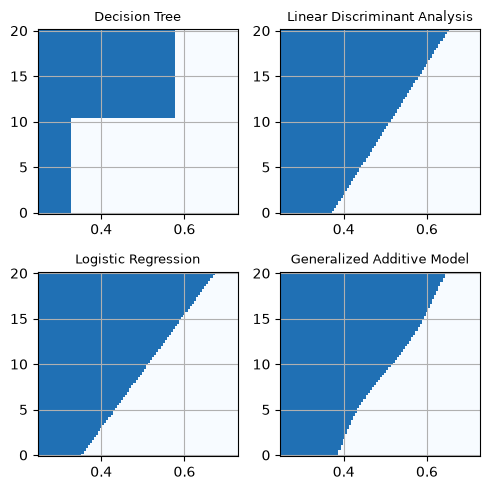

In [41]:
models = {
    'Decision Tree': loan_tree,
    'Linear Discriminant Analysis': loan_lda,
    'Logistic Regression': logit_reg,
    'Generalized Additive Model': gam,
}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(5, 5))

xvalues = np.arange(0.25, 0.73, 0.005)
yvalues = np.arange(-0.1, 20.1, 0.1)
xx, yy = np.meshgrid(xvalues, yvalues)
X = pd.DataFrame({
    'borrower_score': xx.ravel(),
    'payment_inc_ratio': yy.ravel(),
})

boundary = {}

for n, (title, model) in enumerate(models.items()):
    ax = axes[n // 2, n % 2]
    if 'Generalized' in title:
        predict = model.predict(X.values)
        Z = np.array([1 if z > 0.5 else 0 for z in predict])
    else:
        predict = model.predict(X)
        Z = np.array([1 if z == 'default' else 0 for z in predict])
    Z = Z.reshape(xx.shape)
    boundary[title] = yvalues[np.argmax(Z > 0, axis=0)]
    boundary[title][Z[-1,:] == 0] = yvalues[-1]

    c = ax.pcolormesh(xx, yy, Z, cmap='Blues', vmin=0.1, vmax=1.3, shading='auto')
    ax.set_title(title, fontsize=9)
    ax.grid(True)

plt.tight_layout()
plt.show()

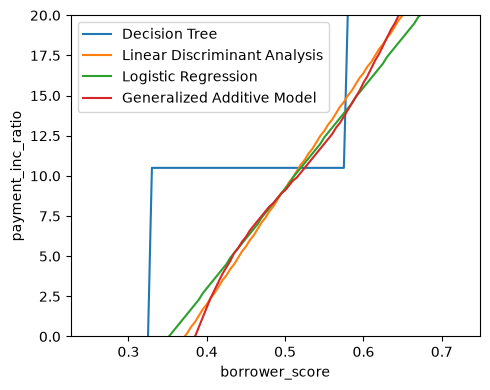

In [42]:
boundary['borrower_score'] = xvalues
boundaries = pd.DataFrame(boundary)

fig, ax = plt.subplots(figsize=(5, 4))
boundaries.plot(x='borrower_score', ax=ax)
ax.set_ylabel('payment_inc_ratio')
ax.set_ylim(0, 20)

plt.tight_layout()
plt.show()

**Interpretasi:** GAM hasil *grid search* memakai dua *spline* `s(0) + s(1)`. Pada plot batas keputusan (biru = diprediksi default), **decision tree** menghasilkan batas berbentuk tangga dengan hanya beberapa aturan: default jika `borrower_score` < sekitar 0,33, atau jika `payment_inc_ratio` > sekitar 10,5 dengan `borrower_score` < sekitar 0,58. Batas **LDA** dan **logistic regression** berupa garis lurus yang hampir berimpit. Batas **GAM** mirip garis tersebut, tetapi sedikit melengkung, terutama di `borrower_score` rendah. Plot gabungan memperjelas hal ini: tiga model halus (LDA, logistic, GAM) sangat mirip di daerah tengah (`borrower_score` 0,4–0,6), tempat data paling banyak, dan baru berbeda di ujung-ujungnya, tempat data jarang. Semua model sepakat bahwa batas `payment_inc_ratio` untuk default naik seiring kenaikan `borrower_score`, sesuai intuisi bisnis. Bentuk tangga decision tree terlihat kurang realistis, misalnya lompatan tajam di `borrower_score` sekitar 0,58.

## Ringkasan Chapter 5
1. **Klasifikasi** memprediksi kelas sebuah record. Umumnya model menghasilkan **probabilitas** atau *propensity*, lalu sebuah **cutoff** mengubahnya menjadi label. *Cutoff* tidak harus 0,5.
2. **Naive Bayes** memakai teorema Bayes dengan asumsi **independensi bersyarat** antar prediktor, diberikan kelasnya. Probabilitasnya bias, tetapi ranking dan klasifikasinya sering baik. Prediktor numerik perlu di-*binning* atau dimodelkan dengan distribusi (misalnya normal).
3. **Linear Discriminant Analysis** mencari kombinasi linear prediktor yang memaksimalkan rasio variasi **antar kelas** terhadap variasi **dalam kelas**, dengan asumsi kovarians yang sama di setiap kelas. Batas keputusannya berupa garis lurus.
4. **Logistic regression** memodelkan **log-odds** (logit) sebagai fungsi linear prediktor. Model ini adalah anggota **GLM** dengan family binomial dan link logit, dan di-*fit* dengan **maximum likelihood**. Kecocokan model diukur dengan **deviance/AIC**.
5. Koefisien logistic regression adalah **log odds ratio**: $\exp(\beta_j)$ adalah perubahan multiplikatif odds. Di scikit-learn, kelas positif adalah kelas kedua secara alfabetis, jadi perhatikan arah tanda koefisien.
6. **Evaluasi:** *confusion matrix* (TP, FP, FN, TN), **accuracy**, **precision**, **recall/sensitivity**, dan **specificity**. Untuk kelas langka, akurasi menyesatkan.
7. **ROC curve** memperlihatkan *trade-off* recall dan specificity di semua *cutoff*. **AUC** merangkumnya (0,5 = acak, 1 = sempurna). **Lift/gains** menilai efektivitas model pada record dengan skor tertinggi.
8. **Data tidak seimbang:** **undersampling** kelas mayoritas, **oversampling** atau **up-weighting** kelas langka, serta **pembangkitan data sintetis** (SMOTE, ADASYN) membuat model lebih sensitif terhadap kelas langka.
9. **Cost-based classification:** pilih *cutoff* berdasarkan **nilai harapan** biaya dan manfaat, bukan hanya akurasi.
10. **Eksplorasi prediksi:** visualisasikan batas keputusan berbagai model (tree, LDA, logistic, GAM) untuk memeriksa apakah perilakunya masuk akal, terutama di daerah yang datanya jarang.